In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('Travel.csv')

In [3]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [4]:
df['ProdTaken'].value_counts()

ProdTaken
0    3968
1     920
Name: count, dtype: int64

In [5]:
# Checking missing values

In [6]:
# for warnings
import warnings
from warnings import filterwarnings
filterwarnings("ignore")

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [9]:
df.shape

(4888, 20)

In [10]:
# check datatype

In [11]:
df.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                         float64
TypeofContact                   str
CityTier                      int64
DurationOfPitch             float64
Occupation                      str
Gender                          str
NumberOfPersonVisiting        int64
NumberOfFollowups           float64
ProductPitched                  str
PreferredPropertyStar       float64
MaritalStatus                   str
NumberOfTrips               float64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting    float64
Designation                     str
MonthlyIncome               float64
dtype: object

In [12]:
df['TypeofContact'].value_counts()

TypeofContact
Self Enquiry       3444
Company Invited    1419
Name: count, dtype: int64

In [13]:
df['Occupation'].value_counts()

Occupation
Salaried          2368
Small Business    2084
Large Business     434
Free Lancer          2
Name: count, dtype: int64

In [14]:
cat_data=df.select_dtypes('str')

In [15]:
cat_data.head()

,TypeofContact,Occupation,Gender,ProductPitched,MaritalStatus,Designation
0,Self Enquiry,Salaried,Female,Deluxe,Single,Manager
1,Company Invited,Salaried,Male,Deluxe,Divorced,Manager
2,Self Enquiry,Free Lancer,Male,Basic,Single,Executive
3,Company Invited,Salaried,Female,Basic,Divorced,Executive
4,Self Enquiry,Small Business,Male,Basic,Divorced,Executive


In [16]:
for i in df.columns:
    df[i].value_counts()

In [17]:
df['Gender'].value_counts()

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64

In [18]:
df['Gender']=df['Gender'].replace("Fe Male","Female")

In [19]:
df['Gender'].value_counts()

Gender
Male      2916
Female    1972
Name: count, dtype: int64

In [20]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64

In [21]:
df['MaritalStatus']=df['MaritalStatus'].replace("Single","Unmarried")

In [22]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Unmarried    1598
Divorced      950
Name: count, dtype: int64

In [23]:
df['Occupation'].value_counts()

Occupation
Salaried          2368
Small Business    2084
Large Business     434
Free Lancer          2
Name: count, dtype: int64

In [24]:
# Handle null values

In [25]:
# find features with null values

In [26]:
features_with_na=[features for features in df.columns if df[features].isnull().sum()>=1]

In [27]:
features_with_na

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [28]:
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [29]:
for features in features_with_na:
    print(features,np.round(df[features].isnull().mean()*100,2),'% missing Values')

Age 4.62 % missing Values
TypeofContact 0.51 % missing Values
DurationOfPitch 5.14 % missing Values
NumberOfFollowups 0.92 % missing Values
PreferredPropertyStar 0.53 % missing Values
NumberOfTrips 2.86 % missing Values
NumberOfChildrenVisiting 1.35 % missing Values
MonthlyIncome 4.77 % missing Values


In [30]:
df[features_with_na].select_dtypes(exclude='str').describe()

,Age,DurationOfPitch,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,NumberOfChildrenVisiting,MonthlyIncome
count,4662.000000,4637.000000,4843.000000,4862.000000,4748.000000,4822.000000,4655.000000
mean,37.622265,15.490835,3.708445,3.581037,3.236521,1.187267,23619.853491
std,9.316387,8.519643,1.002509,0.798009,1.849019,0.857861,5380.698361
min,18.000000,5.000000,1.000000,3.000000,1.000000,0.000000,1000.000000
25%,31.000000,9.000000,3.000000,3.000000,2.000000,1.000000,20346.000000
50%,36.000000,13.000000,4.000000,3.000000,3.000000,1.000000,22347.000000
75%,44.000000,20.000000,4.000000,4.000000,4.000000,2.000000,25571.000000
max,61.000000,127.000000,6.000000,5.000000,22.000000,3.000000,98678.000000


In [31]:
df[features_with_na].columns

Index(['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome'],
      dtype='str')

In [32]:
columns=['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome']

In [33]:
df_numeric=df[features_with_na][columns].select_dtypes('Float64','int64')

In [34]:
df_numeric

,Age,DurationOfPitch,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,NumberOfChildrenVisiting,MonthlyIncome
0,41.0,6.0,3.0,3.0,1.0,0.0,20993.0
1,49.0,14.0,4.0,4.0,2.0,2.0,20130.0
2,37.0,8.0,4.0,3.0,7.0,0.0,17090.0
3,33.0,9.0,3.0,3.0,2.0,1.0,17909.0
4,NaN,8.0,3.0,4.0,1.0,0.0,18468.0
...,...,...,...,...,...,...,...
4883,49.0,9.0,5.0,4.0,2.0,1.0,26576.0
4884,28.0,31.0,5.0,3.0,3.0,2.0,21212.0
4885,52.0,17.0,4.0,4.0,7.0,3.0,31820.0
4886,19.0,16.0,4.0,3.0,3.0,2.0,20289.0


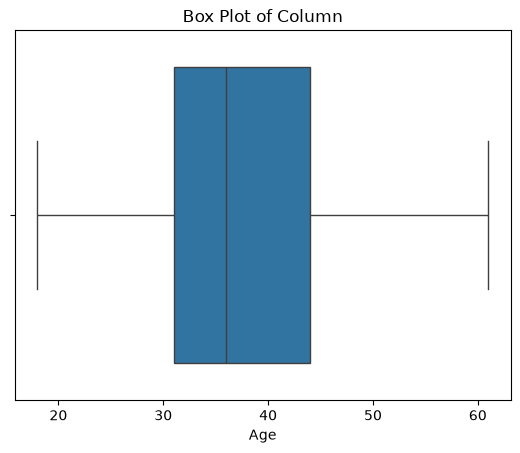

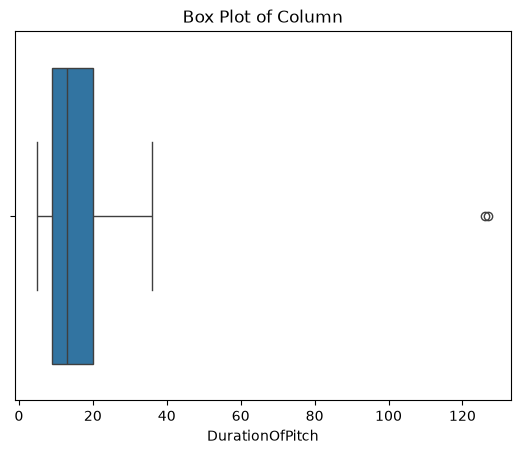

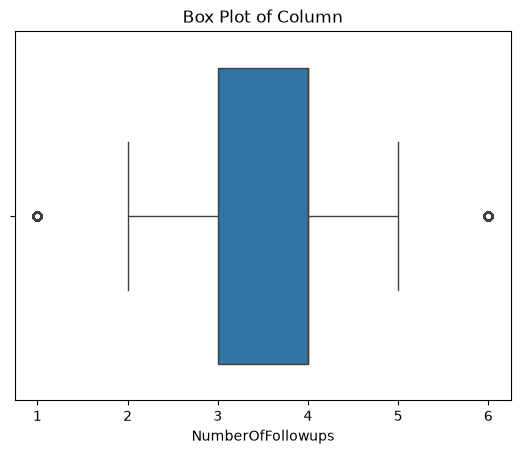

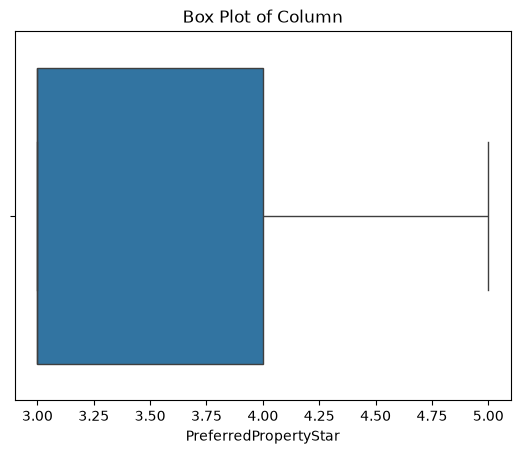

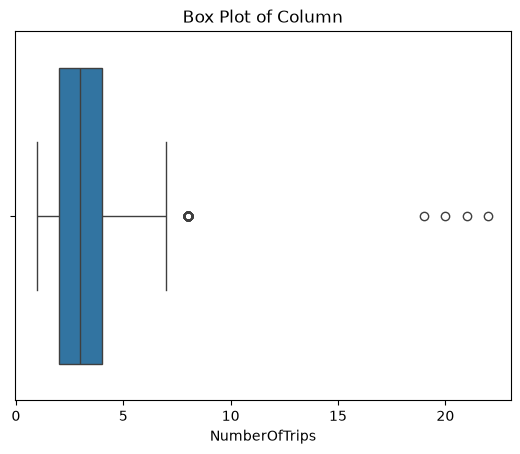

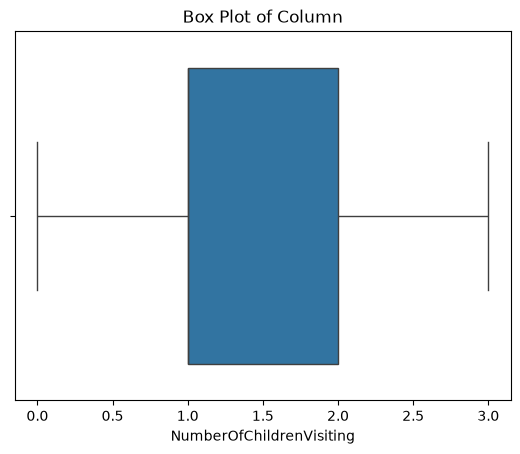

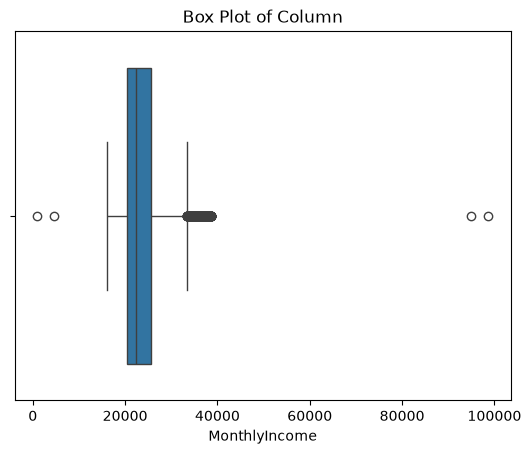

In [35]:
for column in df_numeric.columns:
    plt.figure()
    sns.boxplot(x=df_numeric[column])
    plt.title(f'Box Plot of Column')

In [36]:
features_with_na

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [37]:
df['Age']=df['Age'].fillna(df['Age'].mean())
df['TypeofContact']=df['TypeofContact'].fillna(df['TypeofContact'].mode().iloc[0])
df['DurationOfPitch']=df['DurationOfPitch'].fillna(df['DurationOfPitch'].median())
df['NumberOfFollowups']=df['NumberOfFollowups'].fillna(df['NumberOfFollowups'].median())
df['PreferredPropertyStar']=df['PreferredPropertyStar'].fillna(df['PreferredPropertyStar'].mean())
df['NumberOfTrips']=df['NumberOfTrips'].fillna(df['NumberOfTrips'].median())
df['NumberOfChildrenVisiting']=df['NumberOfChildrenVisiting'].fillna(df['NumberOfChildrenVisiting'].mean())
df['MonthlyIncome']=df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())


In [38]:
df.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [39]:
df.drop('CustomerID',inplace=True,axis=1)

In [40]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='str')

## Feature Engg

In [41]:
df['TotalVisiting']=df['NumberOfPersonVisiting']+df['NumberOfChildrenVisiting']
df.drop(columns=['NumberOfPersonVisiting','NumberOfChildrenVisiting'],inplace=True)

In [42]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfFollowups', 'ProductPitched',
       'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'Designation', 'MonthlyIncome',
       'TotalVisiting'],
      dtype='str')

## Model Training and Train_Test_Split

In [43]:
from sklearn.model_selection import train_test_split

In [44]:
X=df.drop('ProdTaken',axis=1)
y=df['ProdTaken']

In [45]:
X.columns

Index(['Age', 'TypeofContact', 'CityTier', 'DurationOfPitch', 'Occupation',
       'Gender', 'NumberOfFollowups', 'ProductPitched',
       'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'Designation', 'MonthlyIncome',
       'TotalVisiting'],
      dtype='str')

In [46]:
y.value_counts()

ProdTaken
0    3968
1     920
Name: count, dtype: int64

In [47]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [48]:
# column Transformer=used to apply different preprocessing technique to different column of a dataset

In [49]:
from sklearn.compose import ColumnTransformer

## ENCODING

In [50]:
cat_features=X.select_dtypes(include='str').columns
num_features=X.select_dtypes(exclude='str').columns

In [51]:
cat_features

Index(['TypeofContact', 'Occupation', 'Gender', 'ProductPitched',
       'MaritalStatus', 'Designation'],
      dtype='str')

In [52]:
num_features

Index(['Age', 'CityTier', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'MonthlyIncome', 'TotalVisiting'],
      dtype='str')

In [53]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [54]:
# Create an object of both preprocessing

In [55]:
numeric_transformer=StandardScaler()
oh_transformer=OneHotEncoder()

In [56]:
preprocessor=ColumnTransformer([
    ("OneHotEncoder",oh_transformer,cat_features),
    ("StandardScaler",numeric_transformer,num_features)
])

In [57]:
# Apply transformation in trainning data 

In [58]:
X_train=preprocessor.fit_transform(X_train)

In [59]:
# Apply on testing data

In [60]:
X_test=preprocessor.transform(X_test)

In [61]:
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report,f1_score,accuracy_score,precision_score,recall_score

In [62]:
models={
    "Random forest":RandomForestClassifier(),
    "Decision Tree":DecisionTreeClassifier(),
    "Adaboost":AdaBoostClassifier(),
    "Gradient boost":GradientBoostingClassifier(),
    "Xg boost":XGBClassifier()
    }

In [63]:
for i in range(len(list(models))):
    model=list(models.values())[i]

    # model training
    model.fit(X_train,y_train)

    # make predicition
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)

    print(list(models.keys())[i])

    # check training accuracy score 
    print("Training accuracy")
    print(f"accuracy={accuracy_score(y_train,y_train_pred)}")
    print(f"precision={precision_score(y_train,y_train_pred)}")
    print(f"recall={recall_score(y_train,y_train_pred)}")
    print(f"f1-score={f1_score(y_train,y_train_pred)}")


    # check training accuracy score 

    print("Testing accuracy")
    print(f"accuracy={accuracy_score(y_test,y_test_pred)}")
    print(f"precision={precision_score(y_test,y_test_pred)}")
    print(f"recall={recall_score(y_test,y_test_pred)}")
    print(f"f1-score={f1_score(y_test,y_test_pred)}")

    print("--------------------------------------------------")

Random forest
Training accuracy
accuracy=1.0
precision=1.0
recall=1.0
f1-score=1.0
Testing accuracy
accuracy=0.9243353783231084
precision=0.975609756097561
recall=0.6282722513089005
f1-score=0.7643312101910829
--------------------------------------------------
Decision Tree
Training accuracy
accuracy=1.0
precision=1.0
recall=1.0
f1-score=1.0
Testing accuracy
accuracy=0.9130879345603272
precision=0.7819148936170213
recall=0.7696335078534031
f1-score=0.7757255936675461
--------------------------------------------------
Adaboost
Training accuracy
accuracy=0.8506393861892583
precision=0.7935222672064778
recall=0.26886145404663925
f1-score=0.4016393442622951
Testing accuracy
accuracy=0.8404907975460123
precision=0.7868852459016393
recall=0.2513089005235602
f1-score=0.38095238095238093
--------------------------------------------------
Gradient boost
Training accuracy
accuracy=0.8936061381074168
precision=0.8735083532219571
recall=0.5020576131687243
f1-score=0.6376306620209059
Testing accura

In [64]:
# Hyper Parameter tuning

In [65]:
rf_params={
    "max_depth":[5,8,10,15,20],
    "max_feature":[5,7,"auto",8],
    "min_sample_leaf":[2,8,15,20],
    "n_estimators":[100,200,500,1000]

}

In [66]:
random_models=[
    ("RF",RandomForestClassifier(),rf_params)
]

In [67]:
from sklearn.model_selection import RandomizedSearchCV

In [68]:
random_models

[('RF',
  RandomForestClassifier(),
  {'max_depth': [5, 8, 10, 15, 20],
   'max_feature': [5, 7, 'auto', 8],
   'min_sample_leaf': [2, 8, 15, 20],
   'n_estimators': [100, 200, 500, 1000]})]

In [69]:
xgb_params={
    "n_estimators":[100,200,500,1000],
    "max_depth":[3,5,7,10],
    "learning_rate":[0.01,0.05,0.1,0.2]
}

In [70]:
from xgboost import XGBClassifier

In [79]:
xgb_model=XGBClassifier(
    objective="binary:logistic",
    evaluation_metric="logloss",
    use_label_encoder=False
)

In [80]:
best_params=RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_params,
    cv=5,
    random_state=42
)

In [81]:
best_params.fit(X_train,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...obs=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the att

In [82]:
best_params.best_params_

{'n_estimators': 200, 'max_depth': 10, 'learning_rate': 0.2}

In [83]:
best_params.best_score_

np.float64(0.9329923273657288)

In [84]:
models={
    "Xg boost":XGBClassifier()
    }

for i in range(len(list(models))):
    model=list(models.values())[i]

    # model training
    model.fit(X_train,y_train)

    # make predicition
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)

    print(list(models.keys())[i])

    # check training accuracy score 
    print("Training accuracy")
    print(f"accuracy={accuracy_score(y_train,y_train_pred)}")
    print(f"precision={precision_score(y_train,y_train_pred)}")
    print(f"recall={recall_score(y_train,y_train_pred)}")
    print(f"f1-score={f1_score(y_train,y_train_pred)}")


    # check training accuracy score 

    print("Testing accuracy")
    print(f"accuracy={accuracy_score(y_test,y_test_pred)}")
    print(f"precision={precision_score(y_test,y_test_pred)}")
    print(f"recall={recall_score(y_test,y_test_pred)}")
    print(f"f1-score={f1_score(y_test,y_test_pred)}")

    print("--------------------------------------------------")

Xg boost
Training accuracy
accuracy=0.9997442455242966
precision=1.0
recall=0.9986282578875172
f1-score=0.9993136582017845
Testing accuracy
accuracy=0.9468302658486708
precision=0.954248366013072
recall=0.7643979057591623
f1-score=0.8488372093023255
--------------------------------------------------


In [85]:
import joblib

In [88]:
preprocess_job=joblib.dump(preprocessor,'preprocessor.joblib')

In [89]:
joblib.dump(models,'model.joblib')

['model.joblib']